In [1]:
import kagglehub
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score , mean_squared_error , mean_absolute_error

In [2]:
df=pd.read_csv("uber.csv")
df.head()
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


(200000, 9)

In [3]:
df=df.dropna().drop_duplicates()
df=df.drop(columns=["key","unnamed:0"],errors="ignore")
df["pickup_datetime"]=pd.to_datetime(df["pickup_datetime"],errors="coerce" ,utc=True)
df["hour"]=df["pickup_datetime"].dt.hour

df.shape

(199999, 9)

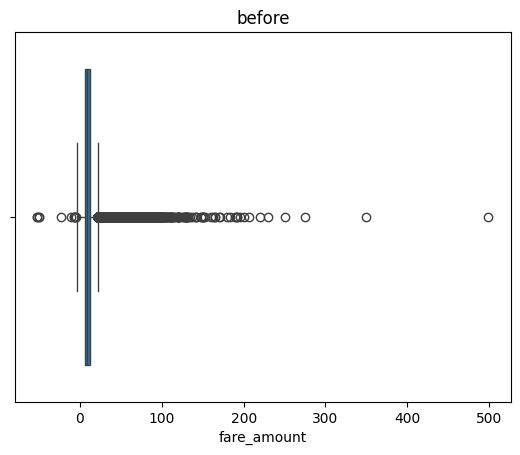

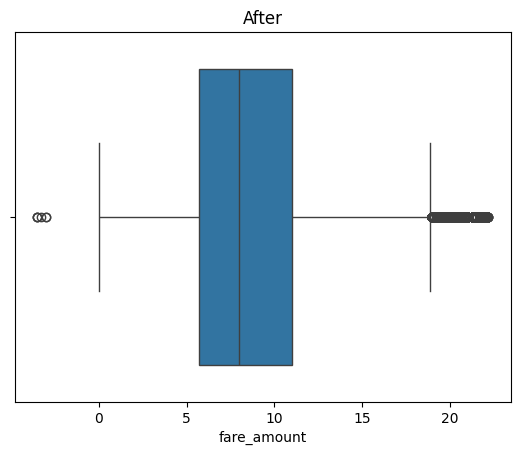

In [4]:
sns.boxplot(x=df["fare_amount"])
plt.title("before")
plt.show()

Q1=df.fare_amount.quantile(0.25)
Q3=df.fare_amount.quantile(0.75)
IQR=Q3-Q1

df=df[(df.fare_amount>=Q1-(1.5*IQR)) & (df.fare_amount<=Q3+(1.5*IQR))]
sns.boxplot(x=df["fare_amount"])
plt.title("After")
plt.show()

                   Unnamed: 0  fare_amount  pickup_longitude  pickup_latitude  \
Unnamed: 0           1.000000    -0.000192          0.000490        -0.001194   
fare_amount         -0.000192     1.000000          0.000367         0.002618   
pickup_longitude     0.000490     0.000367          1.000000        -0.812047   
pickup_latitude     -0.001194     0.002618         -0.812047         1.000000   
dropoff_longitude    0.000835    -0.002413          0.835950        -0.767103   
dropoff_latitude    -0.000488     0.000589         -0.850574         0.684558   
passenger_count      0.002472     0.012618         -0.000751        -0.001604   
hour                 0.001714    -0.013219          0.003544        -0.004675   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
Unnamed: 0                  0.000835         -0.000488         0.002472   
fare_amount                -0.002413          0.000589         0.012618   
pickup_longitude            0.835950         

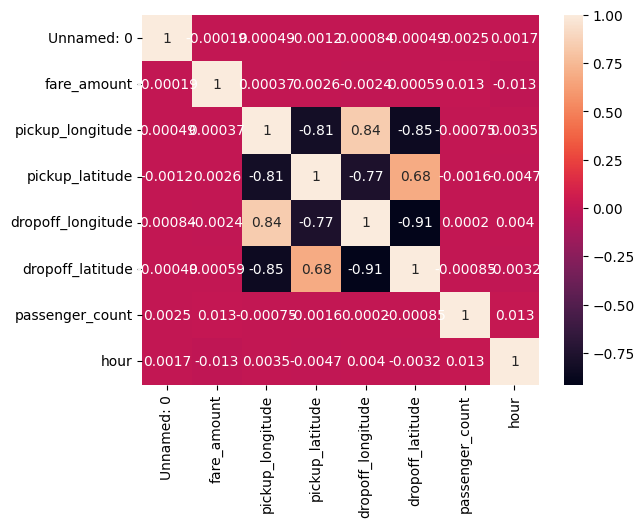

In [5]:
corr=df.corr(numeric_only=True)
print(corr)
sns.heatmap(corr,annot=True)
plt.show()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 182833 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   Unnamed: 0         182833 non-null  int64              
 1   fare_amount        182833 non-null  float64            
 2   pickup_datetime    182833 non-null  datetime64[ns, UTC]
 3   pickup_longitude   182833 non-null  float64            
 4   pickup_latitude    182833 non-null  float64            
 5   dropoff_longitude  182833 non-null  float64            
 6   dropoff_latitude   182833 non-null  float64            
 7   passenger_count    182833 non-null  int64              
 8   hour               182833 non-null  int32              
dtypes: datetime64[ns, UTC](1), float64(5), int32(1), int64(2)
memory usage: 13.3 MB


In [10]:
x = df[["passenger_count", "hour"]]
y=df["fare_amount"]

x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=42
)

lr=LinearRegression()
lr.fit(x_train,y_train)
pred_lr=lr.predict(x_test)

rm=RandomForestRegressor(
    test_size=0.2,random_state=42,max_depth=30,n_estimators=12
)
rm.fit(x_train,y_train)
pred_rm=rm.predict(x_test)

print("Done")

TypeError: RandomForestRegressor.__init__() got an unexpected keyword argument 'test_size'

In [8]:
# Model Evaluation

print("Linear Regression")
print("R2:", r2_score(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("MAE:", mean_absolute_error(y_test, pred_lr))

print("\nRandom Forest")
print("R2:", r2_score(y_test, pred_rm))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_rm)))
print("MAE:", mean_absolute_error(y_test, pred_rm))

Linear Regression
R2: 0.00010923272595986244
RMSE: 4.136569965874322
MAE: 3.2816374969546005

Random Forest
R2: 0.0037972072756742303
RMSE: 4.128934302895153
MAE: 3.277223918094306
